# Cook Inlet DAS: Scholte dispersion and seabed Vs

**Question.** What could a KKFL-S cable segment tell us about seabed shear stiffness, and how do sensing geometry and water depth enter the inference?

### Field facts and teaching assumptions

[Ni, Denolle, Shi et al. (2024), §2 and §4.3](https://doi.org/10.1029/2024JH000247) document Cook Inlet's KKFL-S and TERRA cables, acquired from Homer. They report **9.47 m channel spacing**, **25 Hz raw sampling**, and gauge lengths **17.55 m (June–September)** and **23.93 m (September–December)** in 2023. Their ocean-wave example uses an **80 m average water depth** for a KKFL-S segment. We use those acquisition values and the segment-average depth as context, not as full-route bathymetry. [Shi et al. (2025)](https://doi.org/10.1029/2024JB029728) address offshore earthquake denoising, not a published Scholte Vs profile.

Everything below concerning **sediment velocities, density, thickness, local cable straightness, incidence angles, usable Scholte band, dispersion picks, and time changes is synthetic**. No Cook Inlet waveform or route file is downloaded. A full KKFL-S application needs channel coordinates, local tangent, bathymetry/tides, epoch-specific gauge length, and measured fundamental/higher-mode dispersion with uncertainty.

This tutorial contains an absolute-dispersion Vs fit and a separate small-change depth inversion. The nonlinear fit is a constrained teaching example, not a production structural inversion.


In [1]:
import sys
from pathlib import Path

# Run from the repository root or its tutorials/ directory.
root = Path.cwd().resolve()
if root.name == "tutorials":
    root = root.parent
if not (root / "src" / "gesc").is_dir():
    raise RuntimeError("Run this notebook from the gesc-python checkout.")
sys.path.insert(0, str(root))
sys.path.insert(0, str(root / "src"))
import matplotlib.pyplot as plt
import numpy as np

from gesc import solve_modes
from gesc.inversion import LinearInverseRequest, infer_time_lapse
from gesc.sensitivity import linearize_phase, perturb_model
from tutorials.plotting import emit_metrics, model_table, report_figure, style
from tutorials.scenarios import correlated_covariance, phase_observation

style()
np.set_printoptions(precision=5, suppress=True)
%matplotlib inline

In [2]:
from scipy.linalg import solve_triangular
from scipy.optimize import least_squares

from tutorials.das import along_cable_velocity, horizontal_p_sv_response
from tutorials.scenarios import cook_inlet

model, request = cook_inlet()
model_table(model)
print("Acoustic column:", model.water.model_dump())
channel_spacing_m, gauge_length_m, sample_rate_hz = 9.47, 17.55, 25.0
modes = solve_modes(model, request).fundamental()
f = np.array(request.frequencies_hz)
c0 = np.array([m.phase_velocity_m_s for m in modes])
k = 2 * np.pi * f / c0
wavelength = c0 / f
assert f.max() < sample_rate_hz / 2
assert np.all(wavelength > 2 * channel_spacing_m)
print("Chosen synthetic Scholte frequencies (Hz):", f)
print("Wavelengths (m):", wavelength)
print("The 2.5 Hz decimated stream cannot support this full band.")

Depth (m),Vp (m/s),Vs (m/s),Density (kg/m³)
0–100,1700.0,350.0,1900.0
100–∞,2400.0,800.0,2200.0


Acoustic column: {'depth_m': 80.0, 'sound_speed_m_s': 1480.0, 'density_kg_m3': 1025.0, 'surface_boundary': 'pressure_release'}


Chosen synthetic Scholte frequencies (Hz): [1.5 1.8 2.1 2.5 2.8]
Wavelengths (m): [263.71501 191.52516 155.63586 127.02053 112.34244]
The 2.5 Hz decimated stream cannot support this full band.


## 1. DAS sees axial strain, not a displacement component

For an ideal straight horizontal cable, a P–SV plane wave with $u_x=iUe^{i(kx-\omega t)}$ gives
$$\epsilon_{tt}=-kU\cos^2\theta\,\mathrm{sinc}\!\left(\frac{kL_g\cos\theta}{2}\right),$$
where $\theta$ is the angle between propagation and the cable tangent, and sinc here means $\sin x/x$. Strain rate adds the factor $-i\omega$. The formula assumes perfect coupling and a centered uniform gauge average; it does not predict source excitation, absolute amplitudes, cable mechanics, or pressure sensitivity.

The measured along-cable wavenumber is $k_\parallel=k\cos\theta$. Thus $c_{\rm apparent}=c/|\cos\theta|$: broadside energy can look fast and has weak axial response. A dispersion ridge measured along a curved cable is not automatically the true phase speed.


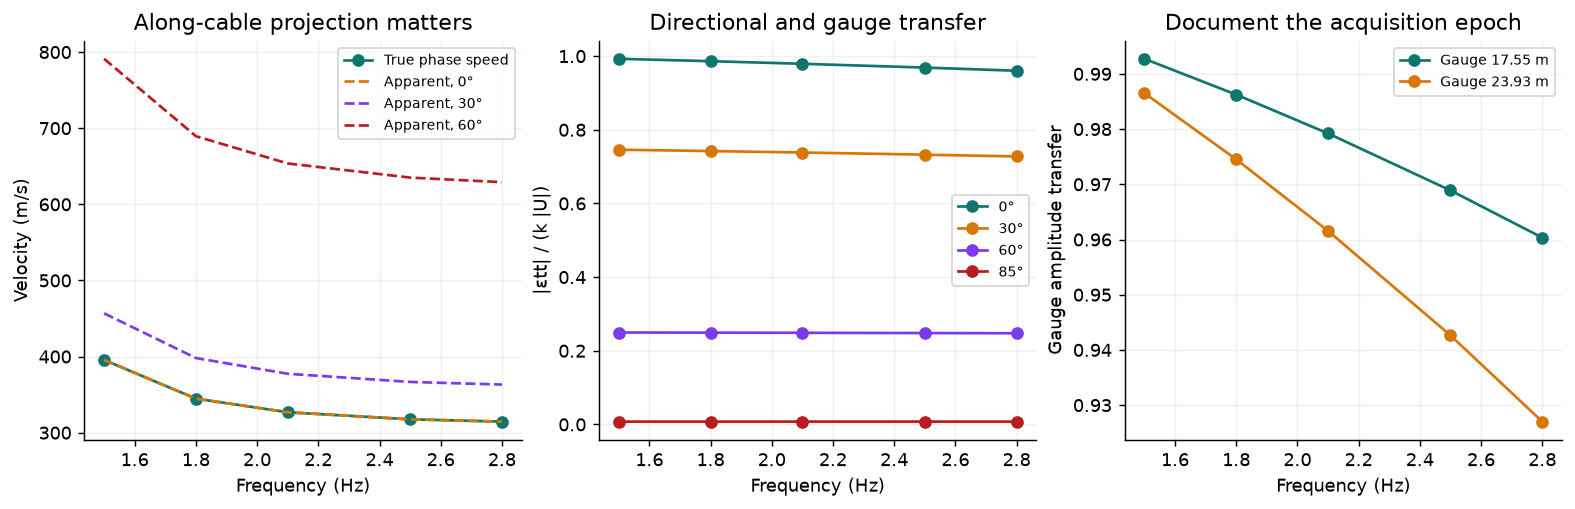

In [3]:
angles_deg = np.array([0.0, 30.0, 60.0, 85.0])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].plot(f, c0, "o-", label="True phase speed")
for angle in angles_deg[:-1]:
    apparent = along_cable_velocity(c0, np.deg2rad(angle))
    axes[0].plot(f, apparent, "--", label=f"Apparent, {angle:g}°")
axes[0].set(
    xlabel="Frequency (Hz)", ylabel="Velocity (m/s)", title="Along-cable projection matters"
)
axes[0].legend(fontsize=8)
for angle in angles_deg:
    transfer = np.abs(horizontal_p_sv_response(k, np.deg2rad(angle), gauge_length_m) / k)
    axes[1].plot(f, transfer, "o-", label=f"{angle:g}°")
axes[1].set(
    xlabel="Frequency (Hz)", ylabel="|εtt| / (k |U|)", title="Directional and gauge transfer"
)
axes[1].legend(fontsize=8)
for gauge in (17.55, 23.93):
    axes[2].plot(
        f, np.abs(horizontal_p_sv_response(k, 0, gauge) / k), "o-", label=f"Gauge {gauge:g} m"
    )
axes[2].set(
    xlabel="Frequency (Hz)",
    ylabel="Gauge amplitude transfer",
    title="Document the acquisition epoch",
)
axes[2].legend(fontsize=8)
plt.show()
# A 60° ridge interpreted as along-cable propagation overestimates c by a factor of two.
np.testing.assert_allclose(along_cable_velocity(c0, np.pi / 3), 2 * c0, rtol=1e-12)

### A small synthetic DAS F–K experiment

Use 192 channels and 64 s at the documented spacing and raw sample rate. Plane-wave phases use an interpolation of the verified dispersion above; amplitudes and coupling are prescribed for this sensing illustration. An analytic ocean-gravity-wave component obeys $\omega^2=gk\tanh(kh)$. GESC does not calculate its loading/excitation.

The synthetic Scholte waves arrive 35° from the cable tangent. Their F–K ridge gives the **along-cable apparent** phase speed. The low-frequency gravity component is a separate ridge, not a Scholte point to invert. This illustration does not extract dispersion automatically; the following inversion uses explicitly generated phase picks and a controlled covariance.


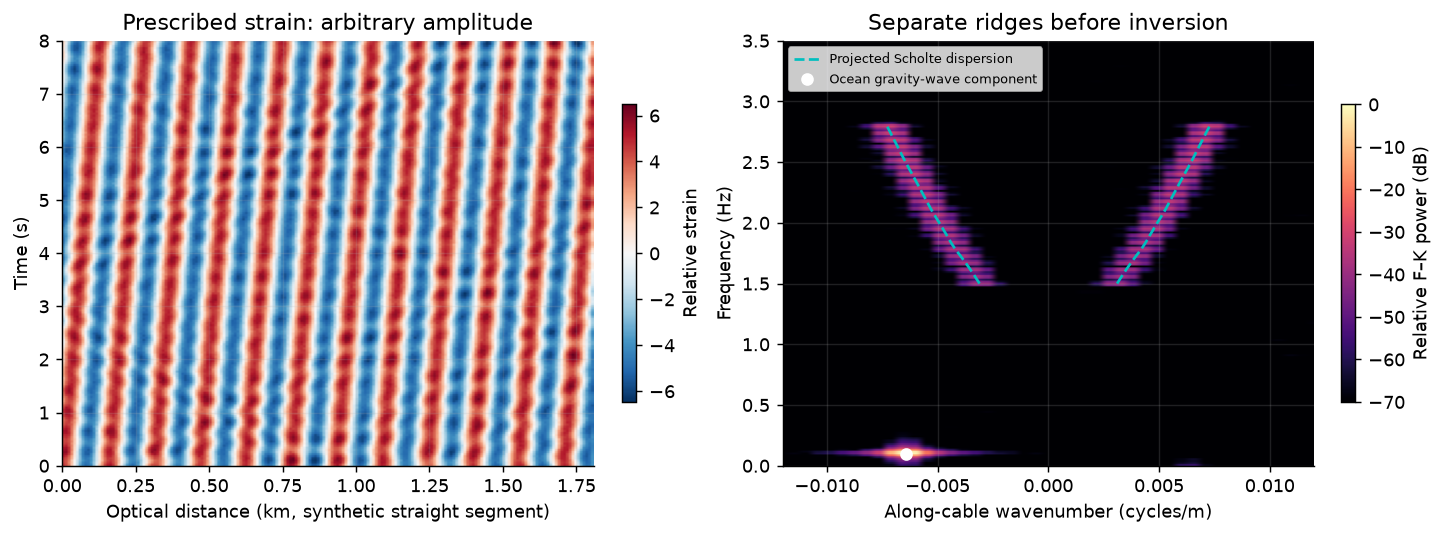

Synthetic array size: (1600, 192) (time, channel)


In [4]:
from scipy.optimize import brentq

nx = 192
times = np.arange(0, 64, 1 / sample_rate_hz)
distance = np.arange(nx) * channel_spacing_m
incidence = np.deg2rad(35.0)
f_synthesis = np.linspace(f.min(), f.max(), 24)
c_synthesis = np.interp(f_synthesis, f, c0)
random_phase = np.random.default_rng(947)
strain = np.zeros((len(times), nx))
for fi, ci in zip(f_synthesis, c_synthesis, strict=True):
    ki = 2 * np.pi * fi / ci
    amplitude = abs(horizontal_p_sv_response(ki, incidence, gauge_length_m)) / np.median(k)
    for direction in (-1, 1):
        phase = (
            direction * ki * np.cos(incidence) * distance[None, :] - 2 * np.pi * fi * times[:, None]
        )
        strain += amplitude * np.cos(phase + random_phase.uniform(0, 2 * np.pi)) / np.sqrt(48)
g = 9.81
ocean_frequency = 0.1
omega_ocean = 2 * np.pi * ocean_frequency
k_ocean = brentq(
    lambda value: g * value * np.tanh(value * model.water.depth_m) - omega_ocean**2, 1e-7, 1.0
)
strain += 5 * np.cos(k_ocean * distance[None, :] - omega_ocean * times[:, None])
strain += random_phase.normal(0, 0.1, strain.shape)
window = np.hanning(len(times))[:, None] * np.hanning(nx)[None, :]
power = np.abs(np.fft.fftshift(np.fft.fft2(strain * window))) ** 2
fft_frequency = np.fft.fftshift(np.fft.fftfreq(len(times), 1 / sample_rate_hz))
fft_wavenumber = np.fft.fftshift(np.fft.fftfreq(nx, channel_spacing_m))
positive = (fft_frequency >= 0) & (fft_frequency <= 3.5)
log_power = 10 * np.log10(np.maximum(power[positive] / power.max(), 1e-12))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
short = times <= 8
image = axes[0].imshow(
    strain[short],
    aspect="auto",
    origin="lower",
    extent=(0, distance[-1] / 1000, 0, 8),
    cmap="RdBu_r",
)
axes[0].set(
    xlabel="Optical distance (km, synthetic straight segment)",
    ylabel="Time (s)",
    title="Prescribed strain: arbitrary amplitude",
)
fig.colorbar(image, ax=axes[0], shrink=0.7, label="Relative strain")
image = axes[1].imshow(
    log_power,
    aspect="auto",
    origin="lower",
    extent=(fft_wavenumber[0], fft_wavenumber[-1], 0, fft_frequency[positive][-1]),
    cmap="magma",
    vmin=-70,
    vmax=0,
)
q_scholte = f_synthesis / c_synthesis * np.cos(incidence)
axes[1].plot(q_scholte, f_synthesis, "c--", label="Projected Scholte dispersion")
axes[1].plot(-q_scholte, f_synthesis, "c--")
# Positive temporal frequency carries negative k for the one-way ocean component.
axes[1].plot(
    -k_ocean / (2 * np.pi), ocean_frequency, "wo", ms=6, label="Ocean gravity-wave component"
)
axes[1].set(
    xlabel="Along-cable wavenumber (cycles/m)",
    ylabel="Frequency (Hz)",
    xlim=(-0.012, 0.012),
    title="Separate ridges before inversion",
)
axes[1].legend(fontsize=7, loc="upper left")
fig.colorbar(image, ax=axes[1], shrink=0.7, label="Relative F–K power (dB)")
plt.show()
print("Synthetic array size:", strain.shape, "(time, channel)")

## 2. Fit absolute Scholte dispersion to seabed Vs

Assume the incidence correction and branch identification have been done. Generate a small structural offset: −3% in log Vs in the top 100 m, +2% below 100 m, and a 2 m higher water column. Keep thickness, Vp, density, water sound speed/density fixed; their baseline uncertainties are omitted.

Fit two absolute Vs values and water depth using a log-dispersion likelihood, correlated frequency errors, and explicit priors. The water prior is centered at 80 m with approximately 5 m standard deviation. This water-depth parameter refers to absolute column depth; it differs from the zero-mean time-change water priors in the monitoring pipeline.


Injected Vs (m/s): [339.65594 816.16107]
MAP Vs (m/s): [339.06058 786.87738]
MAP water depth (m): 80.2351484146679
Local log-parameter SD: [0.00495 0.05316 0.06196]


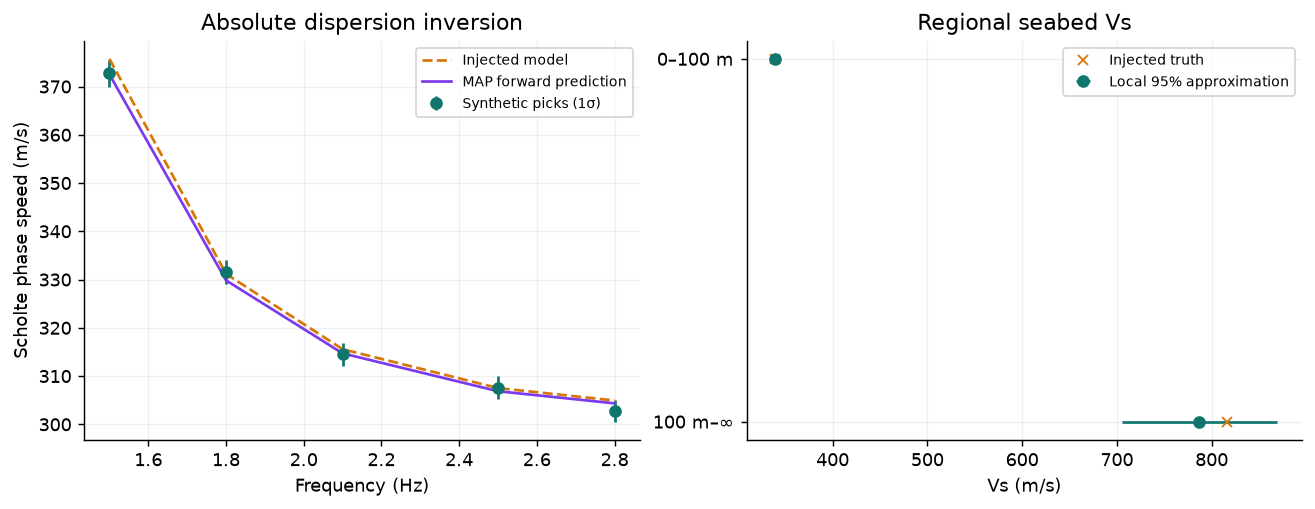

In [5]:
structural_truth = np.array([-0.03, 0.02, np.log(82 / 80)])
forward_cache = {}
forward_qc_errors = []


def forward_log_phase(x):
    key = tuple(np.asarray(x, dtype=float))
    if key not in forward_cache:
        trial = perturb_model(model, x[:2], [x[2], 0.0, 0.0])
        trial_modes = solve_modes(trial, request).fundamental()
        forward_qc_errors.extend(
            max(m.qc.refinement_relative_error, m.qc.bottom_relative_error) for m in trial_modes
        )
        forward_cache[key] = np.log(np.array([m.phase_velocity_m_s for m in trial_modes]) / c0)
    return forward_cache[key]


true_log_dispersion = forward_log_phase(structural_truth)
sigma_log_c = 0.0075  # chosen 0.75% dispersion-pick uncertainty, not field measured
Cpick = correlated_covariance(len(f), sigma_log_c, correlation=0.5)
chol_pick = np.linalg.cholesky(Cpick)
rng = np.random.default_rng(8531)
picked_log_dispersion = true_log_dispersion + chol_pick @ rng.normal(size=len(f))
prior_sd = np.array([0.10, 0.10, 5 / 80])


def residual(x):
    return np.r_[
        solve_triangular(chol_pick, forward_log_phase(x) - picked_log_dispersion, lower=True),
        x / prior_sd,
    ]


def jacobian(x):
    step = 1e-3
    columns = []
    for j in range(3):
        dx = np.zeros(3)
        dx[j] = step
        columns.append((residual(x + dx) - residual(x - dx)) / (2 * step))
    return np.array(columns).T


fit = least_squares(
    residual,
    np.zeros(3),
    jac=jacobian,
    bounds=(-0.15, 0.15),
    max_nfev=15,
    ftol=1e-5,
    xtol=1e-5,
    gtol=1e-5,
)
assert fit.success, fit.message
fit_log = forward_log_phase(fit.x)
map_cov = np.linalg.solve(fit.jac.T @ fit.jac, np.eye(3))
fit_sd = np.sqrt(np.diag(map_cov))
vs_reference = np.array([model.regions[0].top.vs_m_s, model.halfspace.vs_m_s])
true_vs = vs_reference * np.exp(structural_truth[:2])
fit_vs = vs_reference * np.exp(fit.x[:2])
print("Injected Vs (m/s):", true_vs)
print("MAP Vs (m/s):", fit_vs)
print("MAP water depth (m):", model.water.depth_m * np.exp(fit.x[2]))
print("Local log-parameter SD:", fit_sd)
assert np.all(np.abs(fit.x - structural_truth) < 3 * fit_sd)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].errorbar(
    f,
    c0 * np.exp(picked_log_dispersion),
    yerr=c0 * np.exp(picked_log_dispersion) * sigma_log_c,
    fmt="o",
    label="Synthetic picks (1σ)",
)
axes[0].plot(f, c0 * np.exp(true_log_dispersion), "--", label="Injected model")
axes[0].plot(f, c0 * np.exp(fit_log), "-", label="MAP forward prediction")
axes[0].set(
    xlabel="Frequency (Hz)",
    ylabel="Scholte phase speed (m/s)",
    title="Absolute dispersion inversion",
)
axes[0].legend(fontsize=8)
axes[1].errorbar(
    fit_vs, [0, 1], xerr=1.96 * fit_vs * fit_sd[:2], fmt="o", label="Local 95% approximation"
)
axes[1].plot(true_vs, [0, 1], "x", label="Injected truth")
axes[1].set(
    yticks=[0, 1], yticklabels=["0–100 m", "100 m–∞"], xlabel="Vs (m/s)", title="Regional seabed Vs"
)
axes[1].invert_yaxis()
axes[1].legend(fontsize=8)
plt.show()

The structural intervals are a local Gaussian approximation at the MAP. They omit parameterization, thickness, Vp, density, coupling, direction, and absolute bathymetric uncertainty beyond the single depth prior. They do not validate this sediment profile for KKFL-S. A halfspace estimate is an average over its sensitivity, not a measurement at a specified deep horizon.

## 3. Monitor small seabed changes without hiding the tide term

Now return to the original synthetic reference and impose −0.1% in shallow log Vs together with a 0.5 m water-level change. This is a separate time-lapse experiment. Use the fundamental-phase depth pipeline with explicit nuisance priors on water-depth, sound-speed, and density changes.


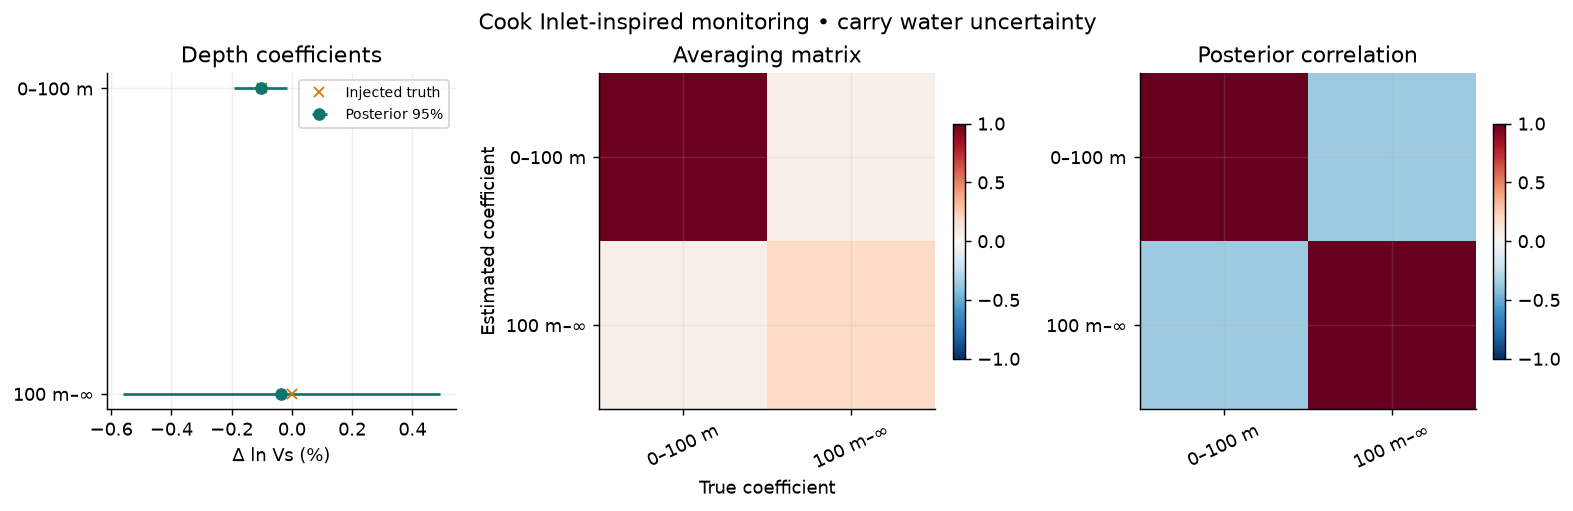

Prior-dominated coefficients: (False, True)
Conditional water change mean: (0.0015327900529882705, -2.179481644662733e-06, 7.446666126777219e-06)


In [6]:
observation = phase_observation(request, sigma=8e-4)
operator = linearize_phase(model, request, observation)
G, H = np.array(operator.g), np.array(operator.h)
time_truth = np.array([-0.001, 0.0])
water_change = np.array([np.log(80.5 / 80), 0.0, 0.0])
changed = solve_modes(perturb_model(model, time_truth, water_change), request).fundamental()
time_data = np.array([m.phase_velocity_m_s for m in changed]) / c0 - 1
linear_error = float(np.max(np.abs(time_data - operator.predict(time_truth, water_change))))
assert linear_error < 0.25 * 8e-4
Cd = correlated_covariance(len(f), 8e-4, correlation=0.5)
report = infer_time_lapse(
    operator,
    LinearInverseRequest(
        data_fractional=tuple(time_data),
        data_covariance=tuple(map(tuple, Cd)),
        prior_mean=(0.0, 0.0),
        prior_covariance=tuple(map(tuple, np.eye(2) * 0.003**2)),
        nuisance_prior_covariance=tuple(
            map(tuple, np.diag(np.array([1 / 80, 0.001, 0.0005]) ** 2))
        ),
    ),
)
report_figure(
    operator, time_truth, report, "Cook Inlet-inspired monitoring • carry water uncertainty"
)
print("Prior-dominated coefficients:", report.prior_dominated)
print("Conditional water change mean:", report.nuisance_mean)
# The inversion uses phase picks. DAS direction and gauge change their observability,
# not G's definition; their uncertainty would need to enter the measured-data likelihood.

## A field workflow for KKFL-S

1. Resolve channel positions, cable tangent, bathymetry, gauge-length epoch, and whether the file contains strain or strain rate. Select approximately straight, locally uniform segments and exclude poor coupling/land channels.
2. Separate ocean-surface-gravity-wave energy from candidate Scholte ridges. Do not feed the 9–15 s ocean-wave band from Ni et al.'s example into a Scholte dispersion inversion. Examine directional spectra and both propagation signs; a single cable cannot uniquely solve all incidence directions.
3. Measure and identify phase-dispersion branches, with geometry and cross-frequency covariance. Check gauge and spatial/temporal aliasing before channel decimation. A geometry-corrected, coherent branch may constrain elastic structure; thousands of neighboring channels do not imply thousands of independent depth constraints.
4. Invert seabed dispersion with water/bathymetry constraints, alternative Vp/density/thickness backgrounds, and explicit resolution. For monitoring, keep tide/temperature/salinity changes separate from seabed elastic changes.

**Try:** choose the later 23.93 m gauge epoch, increase incidence angle, reduce the usable band, or loosen the water prior. Actual observed KKFL-S dispersion and channel metadata can replace the synthetic picks without claiming the chosen geology is field-derived.


In [7]:
assert max(forward_qc_errors) < 0.1 * sigma_log_c
emit_metrics(
    {
        "case": "KKFL-S-informed acquisition, synthetic seabed/picks",
        "field_channel_spacing_m": channel_spacing_m,
        "field_gauge_length_m": gauge_length_m,
        "context_water_depth_m": 80,
        "frequencies_hz": list(f),
        "absolute_fit_success": bool(fit.success),
        "map_vs_m_s": fit_vs.tolist(),
        "map_water_depth_m": float(model.water.depth_m * np.exp(fit.x[2])),
        "max_absolute_forward_qc_error": float(max(forward_qc_errors)),
        "max_time_lapse_linearization_discrepancy": linear_error,
        "checks_passed": True,
    }
)

{
  "case": "KKFL-S-informed acquisition, synthetic seabed/picks",
  "field_channel_spacing_m": 9.47,
  "field_gauge_length_m": 17.55,
  "context_water_depth_m": 80,
  "frequencies_hz": [
    1.5,
    1.8,
    2.1,
    2.5,
    2.8
  ],
  "absolute_fit_success": true,
  "map_vs_m_s": [
    339.06057852857043,
    786.8773831504369
  ],
  "map_water_depth_m": 80.2351484146679,
  "max_absolute_forward_qc_error": 8.141878227174715e-07,
  "max_time_lapse_linearization_discrepancy": 7.933918716156434e-06,
  "checks_passed": true
}

case,"KKFL-S-informed acquisition, synthetic seabed/picks"
field channel spacing m,9.47
field gauge length m,17.55
context water depth m,80
frequencies hz,"[1.5, 1.8, 2.1, 2.5, 2.8]"
absolute fit success,True
map vs m s,"[339.06057852857043, 786.8773831504369]"
map water depth m,80.2351484146679
max absolute forward qc error,8.141878227174715e-07
max time lapse linearization discrepancy,7.933918716156434e-06
checks passed,True
